In [1]:
#import
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append('src/')
from viz import plot_identifiability
from utils import threshold_matrix

%load_ext autoreload
%autoreload 2

#paths
sup_folder = "/data/shared/"
scaffolds_folder = sup_folder + "/HCP/100unrelated/schaefer300/no_hp/scaffolds/whole/"
fc_folder = sup_folder + "/HCP/100unrelated/schaefer300/no_hp/fc/whole/"
figure_folder = "../figures/final/fig2/"

# Create figure folder if it doesn't exist
import os
os.makedirs(figure_folder, exist_ok=True)

import seaborn as sb
import pandas as pd

from pingouin import compute_effsize
from statannotations.Annotator import Annotator

import matplotlib.transforms as transforms
from matplotlib.ticker import FormatStrFormatter

import random

from fingerprinting import compute_idiff, compute_effect_size, compute_success_rate
from tqdm.notebook import tqdm



## Panel A

In [2]:
# LOAD CORRELATION FINGERPRINTING DATA ##

sc = np.load(scaffolds_folder + 'scaffold_correlations_whole.npy')
fc100 = np.load(fc_folder + 'fc_correlations_whole_th100.npy')
fc25 = np.load(fc_folder + 'fc_correlations_whole_th25.npy')
fc1 = np.load(fc_folder + 'fc_correlations_whole_th1.npy')

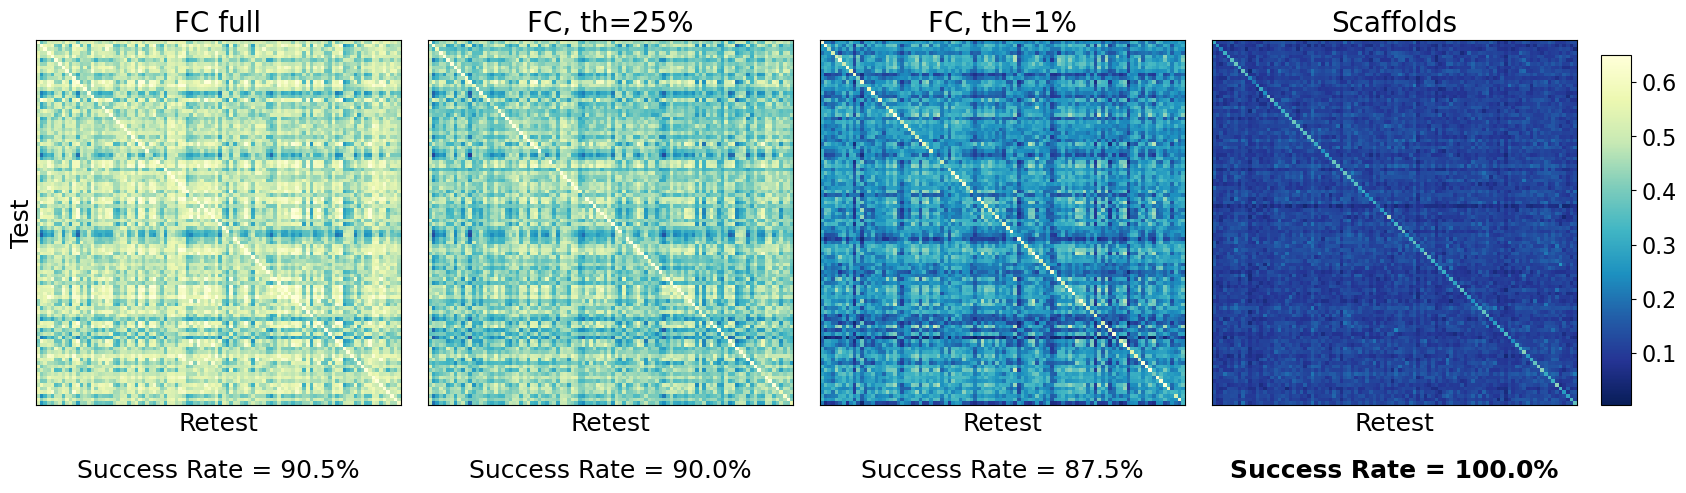

In [3]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, sharey=True, figsize=(20,5))

cmap = 'YlGnBu_r'

# Find global min and max values across all matrices to set the same color scale
all_matrices = [fc100, fc25, fc1, sc]
vmin = min([np.min(mat) for mat in all_matrices])
vmax = max([np.max(mat) for mat in all_matrices])
vmax= 0.65

# Create a shared colormap with the same vmin and vmax
im1 = ax1.imshow(fc100, cmap=cmap, vmin=vmin, vmax=vmax)
ax1.set_title("FC full", fontsize=20)
ax1.set_xticks([])
ax1.set_yticks([])
success_rate1, success_rate2 = compute_success_rate(fc100)
ax1.text(0.5, -0.07, f"Retest", transform=ax1.transAxes, ha='center', fontsize=18)
ax1.text(0.5, -0.2, f'\n\nSuccess Rate = {round((success_rate1+success_rate2)/2, 2)}%', transform=ax1.transAxes, ha='center', fontsize=18)

im2 = ax2.imshow(fc25, cmap=cmap, vmin=vmin, vmax=vmax)
ax2.set_title("FC, th=25%", fontsize=20)
ax2.set_xticks([])
ax2.set_yticks([])
success_rate1, success_rate2 = compute_success_rate(fc25)
ax2.text(0.5, -0.07, f"Retest", transform=ax2.transAxes, ha='center', fontsize=18)
ax2.text(0.5, -0.2, f'\n\nSuccess Rate = {round((success_rate1+success_rate2)/2, 2)}%', transform=ax2.transAxes, ha='center', fontsize=18)

im3 = ax3.imshow(fc1, cmap=cmap, vmin=vmin, vmax=vmax)
ax3.set_title("FC, th=1%", fontsize=20)
ax3.set_xticks([])
ax3.set_yticks([])
success_rate1, success_rate2 = compute_success_rate(fc1)
ax3.text(0.5, -0.07, f"Retest", transform=ax3.transAxes, ha='center', fontsize=18)
ax3.text(0.5, -0.2, f'\n\nSuccess Rate = {round((success_rate1+success_rate2)/2, 2)}%', transform=ax3.transAxes, ha='center', fontsize=18)

im4 = ax4.imshow(sc, cmap=cmap, vmin=vmin, vmax=vmax)
ax4.set_title("Scaffolds", fontsize=20)
ax4.set_xticks([])
ax4.set_yticks([])
success_rate1, success_rate2 = compute_success_rate(sc)
ax4.text(0.5, -0.07, f"Retest", transform=ax4.transAxes, ha='center', fontsize=18)
ax4.text(0.5, -0.2, f' \n\nSuccess Rate = {round((success_rate1+success_rate2)/2, 2)}%', transform=ax4.transAxes, ha='center', fontsize=18, weight='bold')

# Add "Retest" label under each plot
ax1.text(-0.07, 0.5, 'Test', va='center', rotation=90, fontsize=18, transform=ax1.transAxes)

# Create a single colorbar for all plots with position on the right side
plt.subplots_adjust(right=0.9, wspace=0.05, bottom=0.15)  # Adjusted bottom to make room for the shared x-label
cbar_ax = fig.add_axes([0.91, 0.15, 0.015, 0.7])  # [x0, y0, width, height]
cbar = fig.colorbar(im1, cax=cbar_ax)
cbar.ax.tick_params(labelsize=16)

# Save figure
plt.savefig(os.path.join(figure_folder, 'fig2A.png'), dpi=300, bbox_inches='tight')
plt.show()


## Panel B

In [4]:
# Extract intra-subject (diagonal) and inter-subject (off-diagonal) correlations for all conditions
intra_subject_fc100 = np.diag(fc100)
inter_subject_fc100 = fc100[~np.eye(fc100.shape[0], dtype=bool)]

intra_subject_fc25 = np.diag(fc25)
inter_subject_fc25 = fc25[~np.eye(fc25.shape[0], dtype=bool)]

intra_subject_fc1 = np.diag(fc1)
inter_subject_fc1 = fc1[~np.eye(fc1.shape[0], dtype=bool)]

intra_subject_sc = np.diag(sc)
inter_subject_sc = sc[~np.eye(sc.shape[0], dtype=bool)]


# Create dataframes for each condition
data_fc100 = {
    'distribution': (
        ['intra_subject_fc100'] * len(intra_subject_fc100)
        + ['inter_subject_fc100'] * len(inter_subject_fc100)
    ),
    'value': np.concatenate([intra_subject_fc100, inter_subject_fc100])
}

data_fc25 = {
    'distribution': (
        ['intra_subject_fc25'] * len(intra_subject_fc25)
        + ['inter_subject_fc25'] * len(inter_subject_fc25)
    ),
    'value': np.concatenate([intra_subject_fc25, inter_subject_fc25])
}

data_fc1 = {
    'distribution': (
        ['intra_subject_fc1'] * len(intra_subject_fc1)
        + ['inter_subject_fc1'] * len(inter_subject_fc1)
    ),
    'value': np.concatenate([intra_subject_fc1, inter_subject_fc1])
}

data_sc = {
    'distribution': (
        ['intra_subject_sc'] * len(intra_subject_sc)
        + ['inter_subject_sc'] * len(inter_subject_sc)
    ),
    'value': np.concatenate([intra_subject_sc, inter_subject_sc])
}

# Convert to pandas dataframes
df_fc100 = pd.DataFrame(data_fc100)
df_fc25 = pd.DataFrame(data_fc25)
df_fc1 = pd.DataFrame(data_fc1)
df_sc = pd.DataFrame(data_sc)

# Compute effect sizes for each condition
es_fc100 = compute_effsize(df_fc100.loc[df_fc100['distribution'] == 'intra_subject_fc100', 'value'], 
                         df_fc100.loc[df_fc100['distribution'] == 'inter_subject_fc100', 'value'], paired=False)
es_fc25 = compute_effsize(df_fc25.loc[df_fc25['distribution'] == 'intra_subject_fc25', 'value'], 
                        df_fc25.loc[df_fc25['distribution'] == 'inter_subject_fc25', 'value'], paired=False)
es_fc1 = compute_effsize(df_fc1.loc[df_fc1['distribution'] == 'intra_subject_fc1', 'value'], 
                       df_fc1.loc[df_fc1['distribution'] == 'inter_subject_fc1', 'value'], paired=False)
es_sc = compute_effsize(df_sc.loc[df_sc['distribution'] == 'intra_subject_sc', 'value'], 
                      df_sc.loc[df_sc['distribution'] == 'inter_subject_sc', 'value'], paired=False)

/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

intra_subject_fc100 vs. inter_subject_fc100: ES = 3.17


/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

intra_subject_fc25 vs. inter_subject_fc25: ES = 3.37


/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

intra_subject_fc1 vs. inter_subject_fc1: ES = 3.78


/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

intra_subject_sc vs. inter_subject_sc: ES = 7.46


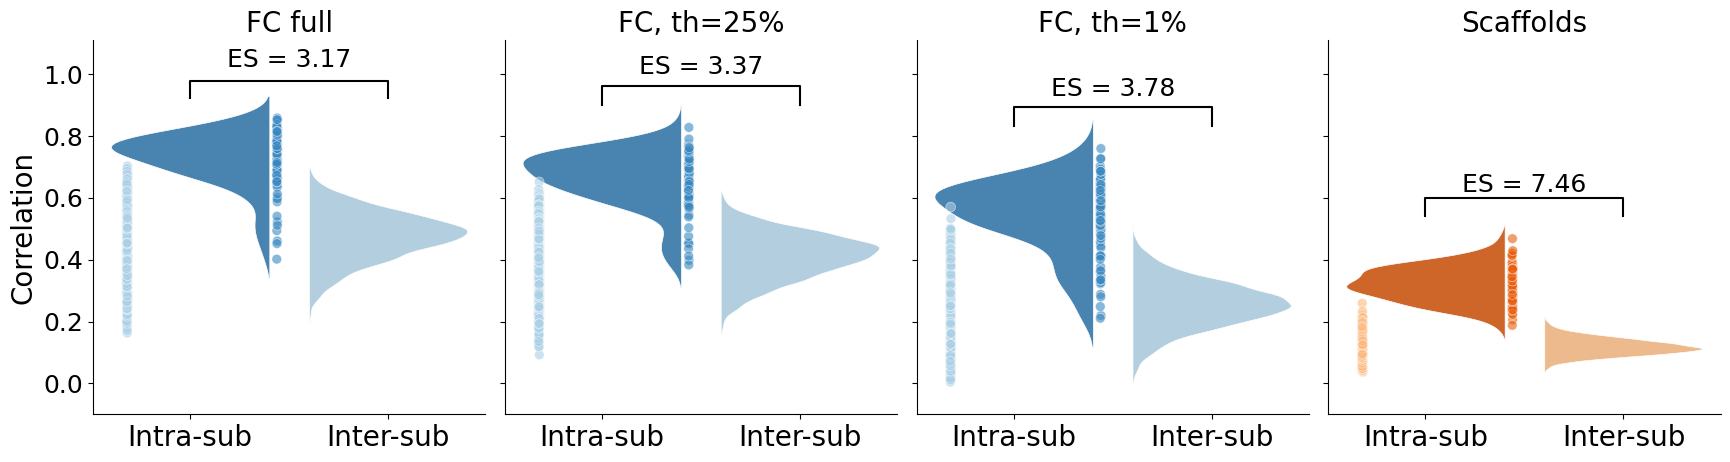

In [5]:
# Color palettes for the plots
blue_palette = sb.color_palette("Blues", n_colors=2)[::-1]  # For FC plots
orange_palette = sb.color_palette("Oranges", n_colors=2)[::-1]  # For scaffold plot
p_size = 7
# Create a 1x4 subplot layout like Panel A
fig, axes = plt.subplots(1, 4, figsize=(21, 5.5), sharey=True)

# FC100 plot
sb.violinplot(x="distribution", y="value", data=df_fc100, ax=axes[0], split=True, inner=None, hue="distribution", palette=blue_palette, legend=False)
sb.stripplot(x="distribution", y="value", data=df_fc100, ax=axes[0], alpha=0.6, size=p_size, jitter=0.002, hue="distribution", palette=blue_palette, legend=False)

# FC25 plot
sb.violinplot(x="distribution", y="value", data=df_fc25, ax=axes[1], split=True, inner=None, hue='distribution', palette=blue_palette, legend=False)
sb.stripplot(x="distribution", y="value", data=df_fc25, ax=axes[1], alpha=0.6, size=p_size, jitter=0.002, hue='distribution', palette=blue_palette, legend=False)

# FC1 plot
sb.violinplot(x="distribution", y="value", data=df_fc1, ax=axes[2], split=True, inner=None, hue='distribution', palette=blue_palette, legend=False)
sb.stripplot(x="distribution", y="value", data=df_fc1, ax=axes[2], alpha=0.6, size=p_size, jitter=0.002, hue='distribution', palette=blue_palette, legend=False)

# Scaffolds plot
sb.violinplot(x="distribution", y="value", data=df_sc, ax=axes[3], split=True, inner=None, hue='distribution', palette=orange_palette, legend=False)
sb.stripplot(x="distribution", y="value", data=df_sc, ax=axes[3], alpha=0.6, size=p_size, jitter=0.002, hue='distribution', palette=orange_palette, legend=False)

# Apply offset for better visualization of points
offset = transforms.ScaledTranslation(0.87, 0, fig.dpi_scale_trans)
for ax in axes:
    for collection in ax.collections[-2:-1]:
        collection.set_transform(collection.get_transform() + offset)
    for collection in ax.collections[-1:]:
        collection.set_transform(collection.get_transform() - offset)
        collection.set_transform(collection.get_transform() - offset)
        collection.set_transform(collection.get_transform() - offset)

# Set titles and labels
axes[0].set_title("FC full", fontsize=20)
axes[1].set_title("FC, th=25%", fontsize=20)
axes[2].set_title("FC, th=1%", fontsize=20)
axes[3].set_title("Scaffolds", fontsize=20)

# Set y-label only for the first subplot
axes[0].set_ylabel('Correlation', fontsize=20)

# Set common y-limit
for ax in axes:
    ax.set_ylim(-0.1, 1)  # Changed lower limit from 0 to -0.2
    ax.set_xlabel('')

# Set x-labels with proper tick positions
for ax in axes:
    ax.set_xticks([0, 1])  # Set tick positions explicitly before setting labels
    ax.set_xticklabels(["Intra-sub", "Inter-sub"], rotation=0, fontsize=20)

# Enhance y-tick visualization
# First, define consistent y-ticks across all subplots
yticks = np.arange(0, 1.1, 0.2)
for i, ax in enumerate(axes):
    ax.set_yticks(yticks)
    if i == 0:
        # Only show y-ticks and labels on the first subplot
        ax.tick_params(axis='y', labelsize=18)
        ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
        # Add subtle grid lines for better readability
        #ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
        ax.set_axisbelow(True)
    else:
        # Remove y-tick labels from other subplots but keep the ticks
        ax.tick_params(axis='y', which='both', left=True, labelleft=False)
        # Add matching grid to other subplots
        #ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
        ax.set_axisbelow(True)

# Enhance violin plot appearance
for i, ax in enumerate(axes):
    # Add subtle background color
    #ax.set_facecolor('#fafafa')
    
    # Customize violin plot elements
    for collection in ax.collections:
        if hasattr(collection, 'set_edgecolor'):
            collection.set_edgecolor('white')
            collection.set_linewidth(0.5)
        if hasattr(collection, 'set_alpha'):
            # Make violins slightly more transparent
            if 'violin' in str(type(collection)).lower():
                collection.set_alpha(0.8)



# Add annotations for each plot with effect sizes (enhanced styling)
pairs = [("intra_subject_fc100", "inter_subject_fc100")]
annot = Annotator(axes[0], pairs=pairs, data=df_fc100, x="distribution", y="value")
annot.set_custom_annotations(['ES = ' + str(round(es_fc100, 2))])
annot.configure(fontsize=18, text_offset=6, line_height=0.05, 
                line_width=1.5, color='black')
annot.annotate()

pairs = [("intra_subject_fc25", "inter_subject_fc25")]
annot = Annotator(axes[1], pairs=pairs, data=df_fc25, x="distribution", y="value")
annot.set_custom_annotations(['ES = ' + str(round(es_fc25, 2))])
annot.configure(fontsize=18, text_offset=5, line_height=0.05,
                line_width=1.5, color='black')
annot.annotate()

pairs = [("intra_subject_fc1", "inter_subject_fc1")]
annot = Annotator(axes[2], pairs=pairs, data=df_fc1, x="distribution", y="value")
annot.set_custom_annotations(['ES = ' + str(round(es_fc1, 2))])
annot.configure(fontsize=18, text_offset=5, line_height=0.05,
                line_width=1.5, color='black')
annot.annotate()

pairs = [("intra_subject_sc", "inter_subject_sc")]
annot = Annotator(axes[3], pairs=pairs, data=df_sc, x="distribution", y="value")
annot.set_custom_annotations(['ES = ' + str(round(es_sc, 2))])
annot.configure(fontsize=18, text_offset=0.5, line_height=0.05,
                line_width=1.5, color='black')
annot.annotate()


sb.despine()

# Add a title to the whole figure
#plt.suptitle('Intra-subject vs Inter-subject Correlations', fontsize=24, y=1.05)

# Adjust spacing between subplots
plt.subplots_adjust(wspace=0.05, bottom=0.2)

# Save figure
plt.savefig(os.path.join(figure_folder, 'fig2B.png'), dpi=300, bbox_inches='tight')
plt.show()

## Panel C

In [6]:
# LOAD CORRELATION FINGERPRINTING DATA ##

sc = np.load(scaffolds_folder + 'scaffold_correlations_whole.npy')
fc100 = np.load(fc_folder + 'fc_correlations_whole_th100.npy')
fc25 = np.load(fc_folder + 'fc_correlations_whole_th25.npy')
fc1 = np.load(fc_folder + 'fc_correlations_whole_th1.npy')

In [7]:
data_dir = '/data/shared/HCP/100unrelated/aal89/'
scaffold_dir = 'scaffolds/whole/'
sc_aal89 = np.load(data_dir+scaffold_dir+'scaffold_correlations_whole.npy')

data_dir = '/data/shared/HCP/100unrelated/schaefer100/'
scaffold_dir = 'scaffolds/whole/'
sc_sch100 = np.load(data_dir+scaffold_dir+'scaffold_correlations_whole.npy')


data_dir = '/data/shared/HCP/100unrelated/shen268/'
scaffold_dir = 'scaffolds/whole/'
sc_shen268 = np.load(data_dir+scaffold_dir+'scaffold_correlations_whole.npy')

data_dir = '/data/shared/HCP/100unrelated/glasser379/'
scaffold_dir = 'scaffolds/whole/'
sc_glass379 = np.load(data_dir+scaffold_dir+'scaffold_correlations_whole.npy')

In [8]:
intra_subject_aal89 = np.diag(sc_aal89)
inter_subject_aal89 = sc_aal89[~np.eye(sc_aal89.shape[0], dtype=bool)]

intra_subject_sch100 = np.diag(sc_sch100)
inter_subject_sch100 = sc_sch100[~np.eye(sc_sch100.shape[0], dtype=bool)]

intra_subject_shen268 = np.diag(sc_shen268)
inter_subject_shen268 = sc_shen268[~np.eye(sc_shen268.shape[0], dtype=bool)]

intra_subject_glass379 = np.diag(sc_glass379)
inter_subject_glass379 = sc_glass379[~np.eye(sc_glass379.shape[0], dtype=bool)]

data_aal89 = {
    'distribution': (
        ['intra_subject_aal89'] * len(intra_subject_aal89)
        + ['inter_subject_aal89'] * len(inter_subject_aal89)
    ),
    'value': np.concatenate([intra_subject_aal89, inter_subject_aal89])
}

data_sch100 = {
    'distribution': (
        ['intra_subject_sch100'] * len(intra_subject_sch100)
        + ['inter_subject_sch100'] * len(inter_subject_sch100)
    ),
    'value': np.concatenate([intra_subject_sch100, inter_subject_sch100])
}

data_shen268 = {
    'distribution': (
        ['intra_subject_shen268'] * len(intra_subject_shen268)
        + ['inter_subject_shen268'] * len(inter_subject_shen268)
    ),
    'value': np.concatenate([intra_subject_shen268, inter_subject_shen268])
}

data_glass379 = {
    'distribution': (
        ['intra_subject_glass379'] * len(intra_subject_glass379)
        + ['inter_subject_glass379'] * len(inter_subject_glass379)
    ),
    'value': np.concatenate([intra_subject_glass379, inter_subject_glass379])
}

df_aal89 = pd.DataFrame(data_aal89)
df_sch100 = pd.DataFrame(data_sch100)
df_shen268 = pd.DataFrame(data_shen268)
df_glass379 = pd.DataFrame(data_glass379)

es = [compute_effsize(df_aal89.loc[df_aal89['distribution'] == 'intra_subject_aal89', 'value'], df_aal89.loc[df_aal89['distribution'] == 'inter_subject_aal89', 'value'], paired=True),
      compute_effsize(df_sch100.loc[df_sch100['distribution'] == 'intra_subject_sch100', 'value'], df_sch100.loc[df_sch100['distribution'] == 'inter_subject_sch100', 'value'], paired=True),
      compute_effsize(df_shen268.loc[df_shen268['distribution'] == 'intra_subject_shen268', 'value'], df_shen268.loc[df_shen268['distribution'] == 'inter_subject_shen268', 'value'], paired=True),
      compute_effsize(df_glass379.loc[df_glass379['distribution'] == 'intra_subject_glass379', 'value'], df_glass379.loc[df_glass379['distribution'] == 'inter_subject_glass379', 'value'], paired=True)]

/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/pingouin/effsize.py:778: UserWarning: x and y have unequal sizes. Switching to paired == False.
  warnings.warn("x and y have unequal sizes. Switching to " "paired == False.")


In [9]:
# Load FC data for different atlases to compare with scaffolds
data_dir_aal89 = '/data/shared/HCP/100unrelated/aal89/'
fc_aal89 = np.load(data_dir_aal89 + 'fc/whole/fc_correlations_whole_th1.npy')

data_dir_sch100 = '/data/shared/HCP/100unrelated/schaefer100/'
fc_sch100 = np.load(data_dir_sch100 + 'fc/whole/fc_correlations_whole_th1.npy')

data_dir_shen268 = '/data/shared/HCP/100unrelated/shen268/'
fc_shen268 = np.load(data_dir_shen268 + 'fc/whole/fc_correlations_whole_th1.npy')

data_dir_glass379 = '/data/shared/HCP/100unrelated/glasser379/'
fc_glass379 = np.load(data_dir_glass379 + 'fc/whole/fc_correlations_whole_th1.npy')

# Extract intra/inter subject correlations for FC
intra_subject_fc_aal89 = np.diag(fc_aal89)
inter_subject_fc_aal89 = fc_aal89[~np.eye(fc_aal89.shape[0], dtype=bool)]

intra_subject_fc_sch100 = np.diag(fc_sch100)
inter_subject_fc_sch100 = fc_sch100[~np.eye(fc_sch100.shape[0], dtype=bool)]

intra_subject_fc_shen268 = np.diag(fc_shen268)
inter_subject_fc_shen268 = fc_shen268[~np.eye(fc_shen268.shape[0], dtype=bool)]

intra_subject_fc_glass379 = np.diag(fc_glass379)
inter_subject_fc_glass379 = fc_glass379[~np.eye(fc_glass379.shape[0], dtype=bool)]

# Create combined dataframes for FC and scaffolds comparison
# AAL89
data_combined_aal89 = {
    'condition': (
        ['FC_intra'] * len(intra_subject_fc_aal89) + 
        ['FC_inter'] * len(inter_subject_fc_aal89) +
        ['SC_intra'] * len(intra_subject_aal89) + 
        ['SC_inter'] * len(inter_subject_aal89)
    ),
    'modality': (
        ['FC'] * (len(intra_subject_fc_aal89) + len(inter_subject_fc_aal89)) +
        ['Scaffolds'] * (len(intra_subject_aal89) + len(inter_subject_aal89))
    ),
    'type': (
        ['Intra-sub'] * len(intra_subject_fc_aal89) + 
        ['Inter-sub'] * len(inter_subject_fc_aal89) +
        ['Intra-sub'] * len(intra_subject_aal89) + 
        ['Inter-sub'] * len(inter_subject_aal89)
    ),
    'value': np.concatenate([intra_subject_fc_aal89, inter_subject_fc_aal89, 
                            intra_subject_aal89, inter_subject_aal89])
}

# Schaefer100
data_combined_sch100 = {
    'condition': (
        ['FC_intra'] * len(intra_subject_fc_sch100) + 
        ['FC_inter'] * len(inter_subject_fc_sch100) +
        ['SC_intra'] * len(intra_subject_sch100) + 
        ['SC_inter'] * len(inter_subject_sch100)
    ),
    'modality': (
        ['FC'] * (len(intra_subject_fc_sch100) + len(inter_subject_fc_sch100)) +
        ['Scaffolds'] * (len(intra_subject_sch100) + len(inter_subject_sch100))
    ),
    'type': (
        ['Intra-sub'] * len(intra_subject_fc_sch100) + 
        ['Inter-sub'] * len(inter_subject_fc_sch100) +
        ['Intra-sub'] * len(intra_subject_sch100) + 
        ['Inter-sub'] * len(inter_subject_sch100)
    ),
    'value': np.concatenate([intra_subject_fc_sch100, inter_subject_fc_sch100, 
                            intra_subject_sch100, inter_subject_sch100])
}

# Shen268
data_combined_shen268 = {
    'condition': (
        ['FC_intra'] * len(intra_subject_fc_shen268) + 
        ['FC_inter'] * len(inter_subject_fc_shen268) +
        ['SC_intra'] * len(intra_subject_shen268) + 
        ['SC_inter'] * len(inter_subject_shen268)
    ),
    'modality': (
        ['FC'] * (len(intra_subject_fc_shen268) + len(inter_subject_fc_shen268)) +
        ['Scaffolds'] * (len(intra_subject_shen268) + len(inter_subject_shen268))
    ),
    'type': (
        ['Intra-sub'] * len(intra_subject_fc_shen268) + 
        ['Inter-sub'] * len(inter_subject_fc_shen268) +
        ['Intra-sub'] * len(intra_subject_shen268) + 
        ['Inter-sub'] * len(inter_subject_shen268)
    ),
    'value': np.concatenate([intra_subject_fc_shen268, inter_subject_fc_shen268, 
                            intra_subject_shen268, inter_subject_shen268])
}

# Glasser379
data_combined_glass379 = {
    'condition': (
        ['FC_intra'] * len(intra_subject_fc_glass379) + 
        ['FC_inter'] * len(inter_subject_fc_glass379) +
        ['SC_intra'] * len(intra_subject_glass379) + 
        ['SC_inter'] * len(inter_subject_glass379)
    ),
    'modality': (
        ['FC'] * (len(intra_subject_fc_glass379) + len(inter_subject_fc_glass379)) +
        ['Scaffolds'] * (len(intra_subject_glass379) + len(inter_subject_glass379))
    ),
    'type': (
        ['Intra-sub'] * len(intra_subject_fc_glass379) + 
        ['Inter-sub'] * len(inter_subject_fc_glass379) +
        ['Intra-sub'] * len(intra_subject_glass379) + 
        ['Inter-sub'] * len(inter_subject_glass379)
    ),
    'value': np.concatenate([intra_subject_fc_glass379, inter_subject_fc_glass379, 
                            intra_subject_glass379, inter_subject_glass379])
}

# Convert to dataframes
df_combined_aal89 = pd.DataFrame(data_combined_aal89)
df_combined_sch100 = pd.DataFrame(data_combined_sch100)
df_combined_shen268 = pd.DataFrame(data_combined_shen268)
df_combined_glass379 = pd.DataFrame(data_combined_glass379)

/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

FC_Intra-sub vs. FC_Inter-sub: ES = 1.37
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Scaffolds_Intra-sub vs. Scaffolds_Inter-sub: ES = 2.09


/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

FC_Intra-sub vs. FC_Inter-sub: ES = 1.37


/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Scaffolds_Intra-sub vs. Scaffolds_Inter-sub: ES = 2.72


... (4 outputs left out)

/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

FC_Intra-sub vs. FC_Inter-sub: ES = 4.58


/home/spoetto/miniconda3/envs/tda/lib/python3.13/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Scaffolds_Intra-sub vs. Scaffolds_Inter-sub: ES = 8.04


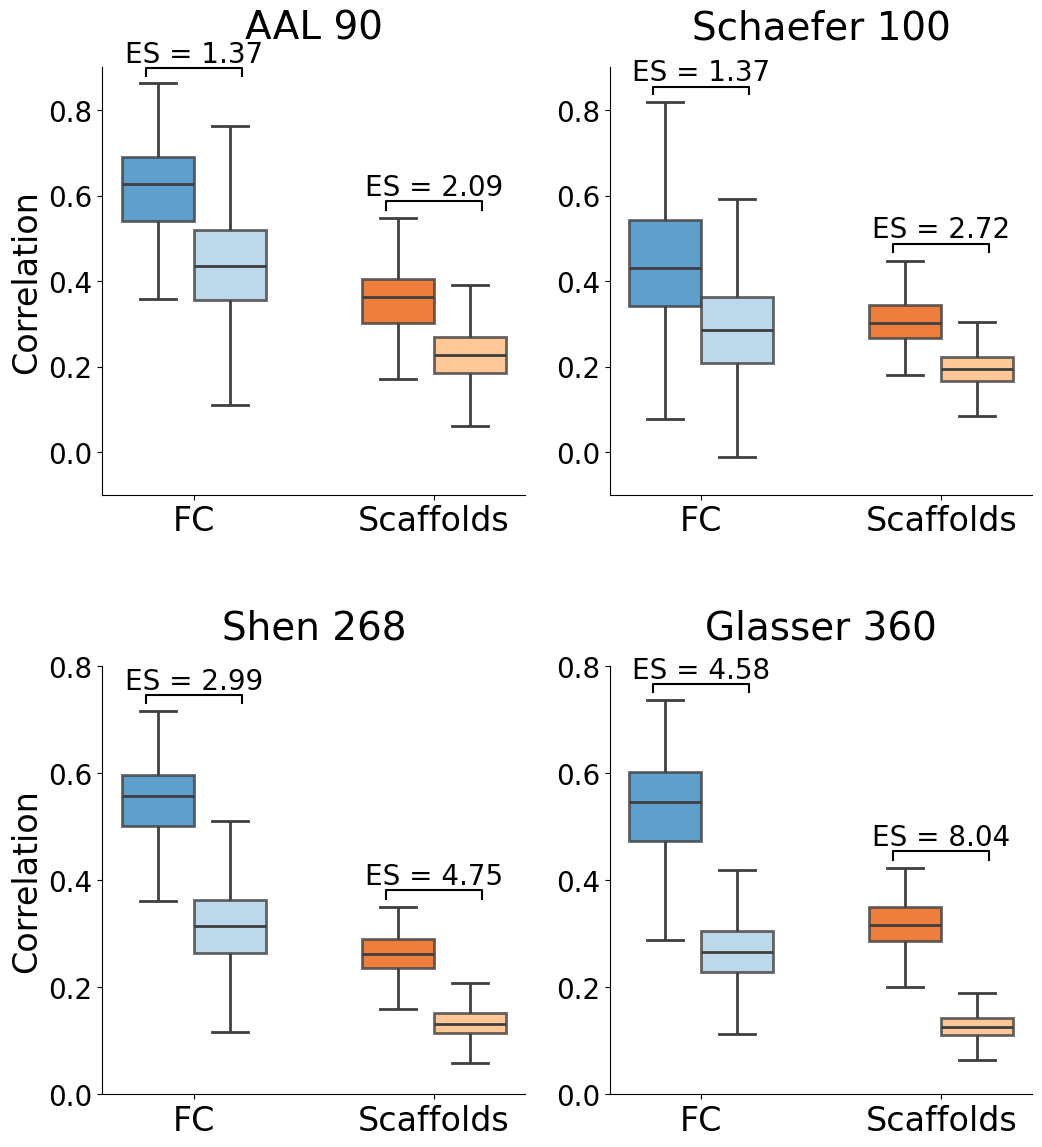

In [10]:
# Create 2x2 subplot layout with boxplots comparing FC and scaffolds
fig, axes = plt.subplots(2, 2, figsize=(12, 13))
axes = axes.ravel()

# Define color palettes
blue_palette = sb.color_palette("Blues", n_colors=2)[::-1]  # For FC data
orange_palette = sb.color_palette("Oranges", n_colors=2)[::-1]  # For scaffold data

# AAL89 plot
sb.boxplot(x="modality", y="value", hue="type", data=df_combined_aal89, ax=axes[0], 
           dodge=True, showfliers=False, linewidth=2, width=0.6)

# Schaefer100 plot
sb.boxplot(x="modality", y="value", hue="type", data=df_combined_sch100, ax=axes[1], 
           dodge=True, showfliers=False, linewidth=2, width=0.6)


# Shen268 plot
sb.boxplot(x="modality", y="value", hue="type", data=df_combined_shen268, ax=axes[2], 
           dodge=True, showfliers=False, linewidth=2, width=0.6)


# Glasser379 plot
sb.boxplot(x="modality", y="value", hue="type", data=df_combined_glass379, ax=axes[3], 
           dodge=True, showfliers=False, linewidth=2, width=0.6)


# Manually set colors for all subplots
for ax_idx, ax in enumerate(axes):
    # Color the boxplots
    for i, patch in enumerate(ax.patches[:4]):  # Only first 4 patches are boxplots
        if i == 0:  # FC-Intra
            patch.set_facecolor(blue_palette[0])
            patch.set_alpha(0.8)
        elif i == 1:  # FC-Inter
            patch.set_facecolor(orange_palette[0])
            patch.set_alpha(0.8)
        elif i == 2:  # Scaffolds-Intra
            patch.set_facecolor(blue_palette[1])
            patch.set_alpha(0.8)
        elif i == 3:  # Scaffolds-Inter
            patch.set_facecolor(orange_palette[1])
            patch.set_alpha(0.8)

# Calculate and add effect size annotations for each comparison
# For FC Intra vs Inter
fc_aal89_es = compute_effsize(
    df_combined_aal89[(df_combined_aal89['modality'] == 'FC') & (df_combined_aal89['type'] == 'Intra-sub')]['value'],
    df_combined_aal89[(df_combined_aal89['modality'] == 'FC') & (df_combined_aal89['type'] == 'Inter-sub')]['value'],
    paired=False
)
fc_sch100_es = compute_effsize(
    df_combined_sch100[(df_combined_sch100['modality'] == 'FC') & (df_combined_sch100['type'] == 'Intra-sub')]['value'],
    df_combined_sch100[(df_combined_sch100['modality'] == 'FC') & (df_combined_sch100['type'] == 'Inter-sub')]['value'],
    paired=False
)
fc_shen268_es = compute_effsize(
    df_combined_shen268[(df_combined_shen268['modality'] == 'FC') & (df_combined_shen268['type'] == 'Intra-sub')]['value'],
    df_combined_shen268[(df_combined_shen268['modality'] == 'FC') & (df_combined_shen268['type'] == 'Inter-sub')]['value'],
    paired=False
)
fc_glass379_es = compute_effsize(
    df_combined_glass379[(df_combined_glass379['modality'] == 'FC') & (df_combined_glass379['type'] == 'Intra-sub')]['value'],
    df_combined_glass379[(df_combined_glass379['modality'] == 'FC') & (df_combined_glass379['type'] == 'Inter-sub')]['value'],
    paired=False
)

# For Scaffold Intra vs Inter
sc_aal89_es = compute_effsize(
    df_combined_aal89[(df_combined_aal89['modality'] == 'Scaffolds') & (df_combined_aal89['type'] == 'Intra-sub')]['value'],
    df_combined_aal89[(df_combined_aal89['modality'] == 'Scaffolds') & (df_combined_aal89['type'] == 'Inter-sub')]['value'],
    paired=False
)
sc_sch100_es = compute_effsize(
    df_combined_sch100[(df_combined_sch100['modality'] == 'Scaffolds') & (df_combined_sch100['type'] == 'Intra-sub')]['value'],
    df_combined_sch100[(df_combined_sch100['modality'] == 'Scaffolds') & (df_combined_sch100['type'] == 'Inter-sub')]['value'],
    paired=False
)
sc_shen268_es = compute_effsize(
    df_combined_shen268[(df_combined_shen268['modality'] == 'Scaffolds') & (df_combined_shen268['type'] == 'Intra-sub')]['value'],
    df_combined_shen268[(df_combined_shen268['modality'] == 'Scaffolds') & (df_combined_shen268['type'] == 'Inter-sub')]['value'],
    paired=False
)
sc_glass379_es = compute_effsize(
    df_combined_glass379[(df_combined_glass379['modality'] == 'Scaffolds') & (df_combined_glass379['type'] == 'Intra-sub')]['value'],
    df_combined_glass379[(df_combined_glass379['modality'] == 'Scaffolds') & (df_combined_glass379['type'] == 'Inter-sub')]['value'],
    paired=False
)


# Add effect size annotations using statannotations.Annotator
# For AAL89 - FC comparison
pairs_fc = [(('FC', 'Intra-sub'), ('FC', 'Inter-sub'))]
annot_fc_aal89 = Annotator(axes[0], pairs=pairs_fc, data=df_combined_aal89, 
                          x='modality', y='value', hue='type')
annot_fc_aal89.set_custom_annotations([f'ES = {fc_aal89_es:.2f}'])
annot_fc_aal89.configure(fontsize=20, text_offset=0.01, line_height=0.02,
                        line_width=1.5, color='black')
annot_fc_aal89.annotate(line_offset_to_group=0.02)

# For AAL89 - Scaffold comparison
pairs_sc = [(('Scaffolds', 'Intra-sub'), ('Scaffolds', 'Inter-sub'))]
annot_sc_aal89 = Annotator(axes[0], pairs=pairs_sc, data=df_combined_aal89,
                          x='modality', y='value', hue='type')
annot_sc_aal89.set_custom_annotations([f'ES = {sc_aal89_es:.2f}'])
annot_sc_aal89.configure(fontsize=20, text_offset=0.02, line_height=0.02,
                        line_width=1.5, color='black')
annot_sc_aal89.annotate(line_offset_to_group=0.02)

# For Schaefer100 - FC comparison
annot_fc_sch100 = Annotator(axes[1], pairs=pairs_fc, data=df_combined_sch100,
                           x='modality', y='value', hue='type')
annot_fc_sch100.set_custom_annotations([f'ES = {fc_sch100_es:.2f}'])
annot_fc_sch100.configure(fontsize=20, text_offset=0.02, line_height=0.02,
                         line_width=1.5, color='black')
annot_fc_sch100.annotate(line_offset_to_group=0.02)

# For Schaefer100 - Scaffold comparison
annot_sc_sch100 = Annotator(axes[1], pairs=pairs_sc, data=df_combined_sch100,
                           x='modality', y='value', hue='type')
annot_sc_sch100.set_custom_annotations([f'ES = {sc_sch100_es:.2f}'])
annot_sc_sch100.configure(fontsize=20, text_offset=0.02, line_height=0.02,
                         line_width=1.5, color='black')
annot_sc_sch100.annotate(line_offset_to_group=0.02)

# For Shen268 - FC comparison
annot_fc_shen268 = Annotator(axes[2], pairs=pairs_fc, data=df_combined_shen268,
                            x='modality', y='value', hue='type')
annot_fc_shen268.set_custom_annotations([f'ES = {fc_shen268_es:.2f}'])
annot_fc_shen268.configure(fontsize=20, text_offset=0.02, line_height=0.02,
                          line_width=1.5, color='black')
annot_fc_shen268.annotate(line_offset_to_group=0.02)

# For Shen268 - Scaffold comparison
annot_sc_shen268 = Annotator(axes[2], pairs=pairs_sc, data=df_combined_shen268,
                            x='modality', y='value', hue='type')
annot_sc_shen268.set_custom_annotations([f'ES = {sc_shen268_es:.2f}'])
annot_sc_shen268.configure(fontsize=20, text_offset=0.02, line_height=0.02,
                          line_width=1.5, color='black')
annot_sc_shen268.annotate(line_offset_to_group=0.02)

# For Glasser379 - FC comparison
annot_fc_glass379 = Annotator(axes[3], pairs=pairs_fc, data=df_combined_glass379,
                             x='modality', y='value', hue='type')
annot_fc_glass379.set_custom_annotations([f'ES = {fc_glass379_es:.2f}'])
annot_fc_glass379.configure(fontsize=20, text_offset=0.02, line_height=0.02,
                           line_width=1.5, color='black')
annot_fc_glass379.annotate(line_offset_to_group=0.02)

# For Glasser379 - Scaffold comparison
annot_sc_glass379 = Annotator(axes[3], pairs=pairs_sc, data=df_combined_glass379,
                             x='modality', y='value', hue='type')
annot_sc_glass379.set_custom_annotations([f'ES = {sc_glass379_es:.2f}'])
annot_sc_glass379.configure(fontsize=20, text_offset=0.02, line_height=0.02,
                           line_width=1.5, color='black')
annot_sc_glass379.annotate(line_offset_to_group=0.02)

# Set titles and labels
axes[0].set_title("AAL 90", fontsize=28, pad=20)
axes[1].set_title("Schaefer 100", fontsize=28, pad=20)
axes[2].set_title("Shen 268", fontsize=28, pad=20)
axes[3].set_title("Glasser 360", fontsize=28, pad=20)

# Set y-labels
axes[0].set_ylabel('Correlation', fontsize=24)
axes[1].set_ylabel('')
axes[2].set_ylabel('Correlation', fontsize=24)
axes[3].set_ylabel('')


yticks = np.linspace(0, 0.8, 5)  # Generate 6 ticks from 0 to 1.0
    
# Apply same y-ticks to all subplots
axes[0].set_ylim(-0.1, 0.9)
axes[1].set_ylim(-0.1, 0.9)
axes[2].set_ylim(0, 0.8)
axes[3].set_ylim(0, 0.8)

for ax in axes:
    ax.set_yticks(yticks)
    ax.tick_params(axis='y', labelsize=20)


# Set x-labels for all subplots
for i, ax in enumerate(axes):
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["FC", "Scaffolds"], rotation=0, fontsize=24)
    ax.set_xlabel('')

# Remove legends
for ax in axes:
    handles, labels = ax.get_legend_handles_labels()
    if hasattr(ax, 'legend_') and ax.legend_:
        ax.legend_.remove()


sb.despine()

# Increase space between subplots
plt.subplots_adjust(hspace=0.4)

# Make room for legend
plt.subplots_adjust(top=0.90)

# Save figure
plt.savefig(os.path.join(figure_folder, 'fig2C_boxplots.png'), dpi=300, bbox_inches='tight')
plt.show()

# Panel D - Success Rate across Window Sizes with Bootstrap (Random Window Selection)

In [11]:
# Compute success rate across different window sizes using bootstrap methods
# For each bootstrap iteration, randomly select one window per subject
widths = [1100,1000,900,800,700,600,500,400,300,200,100,50]
data_dir = sup_folder + '/HCP/100unrelated/schaefer300/no_hp/'
n_subs = 100
n_bootstrap = 100  # Number of bootstrap samples

# Storage for success rate results
success_rate_fc = {}
success_rate_sc = {}

for width in widths:
    print(f'Processing window size: {width}')
    
    fc0 = []
    fc1 = []
    sc0 = []
    sc1 = []
    
    # Load data for this window size
    for sub in os.listdir(data_dir+f'fc/{width}/'):
        fcs = np.load(data_dir+f'fc/{width}/{sub}')
        scs = np.load(data_dir+f'scaffolds/{width}/freq/{sub[:6]}')
        n = fcs.shape[0]
        fc0.append(fcs[:n//2])
        fc1.append(fcs[n//2:])
        sc0.append(scs[:n//2])
        sc1.append(scs[n//2:])
    
    fc0 = np.array(fc0).reshape(-1,300,300)
    fc1 = np.array(fc1).reshape(-1,300,300)
    
    # Threshold FC
    fc0 = np.array([threshold_matrix(f,1).flatten() for f in fc0])
    fc1 = np.array([threshold_matrix(f,1).flatten() for f in fc1])
    
    sc0 = np.array(sc0).reshape(-1,300,300)
    sc1 = np.array(sc1).reshape(-1,300,300)
    sc0 = np.array([s.flatten() for s in sc0])
    sc1 = np.array([s.flatten() for s in sc1])
    
    m = fc0.shape[0]
    n_winps = int(fc0.shape[0]/n_subs)  # n_windows per subject
    
    # Compute correlations fc and scaffolds
    corrs_fc = np.corrcoef(fc0,fc1)[m:,:m]
    corrs_sc = np.corrcoef(sc0,sc1)[m:,:m]
    
    # Bootstrap sampling for success rate with random window selection
    fc_success_rate1_bootstrap = []
    fc_success_rate2_bootstrap = []
    sc_success_rate1_bootstrap = []
    sc_success_rate2_bootstrap = []
    
    for bootstrap_iter in range(n_bootstrap):
        # Create similarity matrices by randomly selecting one window per subject
        fc_similarity_matrix = np.zeros((n_subs, n_subs))
        sc_similarity_matrix = np.zeros((n_subs, n_subs))
        
        # For each subject pair, randomly select one window from each subject
        for i in range(n_subs):
            for j in range(n_subs):
                # Randomly select one window from subject i and one from subject j
                win_i = np.random.randint(0, n_winps)
                win_j = np.random.randint(0, n_winps)
                
                # Get the correlation between these specific windows
                global_idx_i = i * n_winps + win_i
                global_idx_j = j * n_winps + win_j
                
                fc_similarity_matrix[i, j] = corrs_fc[global_idx_i, global_idx_j]
                sc_similarity_matrix[i, j] = corrs_sc[global_idx_i, global_idx_j]
        
        # Compute success rate for this bootstrap sample
        fc_sr1, fc_sr2 = compute_success_rate(fc_similarity_matrix, kind='corr')
        sc_sr1, sc_sr2 = compute_success_rate(sc_similarity_matrix, kind='corr')
        
        fc_success_rate1_bootstrap.append(fc_sr1)
        fc_success_rate2_bootstrap.append(fc_sr2)
        sc_success_rate1_bootstrap.append(sc_sr1)
        sc_success_rate2_bootstrap.append(sc_sr2)
    
    # Compute mean success rate (average of both directions)
    fc_success_rate_mean_bootstrap = [(sr1 + sr2) / 2 for sr1, sr2 in zip(fc_success_rate1_bootstrap, fc_success_rate2_bootstrap)]
    sc_success_rate_mean_bootstrap = [(sr1 + sr2) / 2 for sr1, sr2 in zip(sc_success_rate1_bootstrap, sc_success_rate2_bootstrap)]
    
    # Store results
    success_rate_fc[width] = {
        'mean': np.mean(fc_success_rate_mean_bootstrap),
        'std': np.std(fc_success_rate_mean_bootstrap),
        'bootstrap_samples': fc_success_rate_mean_bootstrap,
        'sr1_mean': np.mean(fc_success_rate1_bootstrap),
        'sr2_mean': np.mean(fc_success_rate2_bootstrap)
    }
    
    success_rate_sc[width] = {
        'mean': np.mean(sc_success_rate_mean_bootstrap),
        'std': np.std(sc_success_rate_mean_bootstrap),
        'bootstrap_samples': sc_success_rate_mean_bootstrap,
        'sr1_mean': np.mean(sc_success_rate1_bootstrap),
        'sr2_mean': np.mean(sc_success_rate2_bootstrap)
    }

print('Success rate computation completed!')

Processing window size: 1100
Processing window size: 1000
Processing window size: 900
Processing window size: 800
Processing window size: 700
Processing window size: 600
Processing window size: 500
Processing window size: 400
Processing window size: 300
Processing window size: 200
Processing window size: 100
Processing window size: 50
Success rate computation completed!


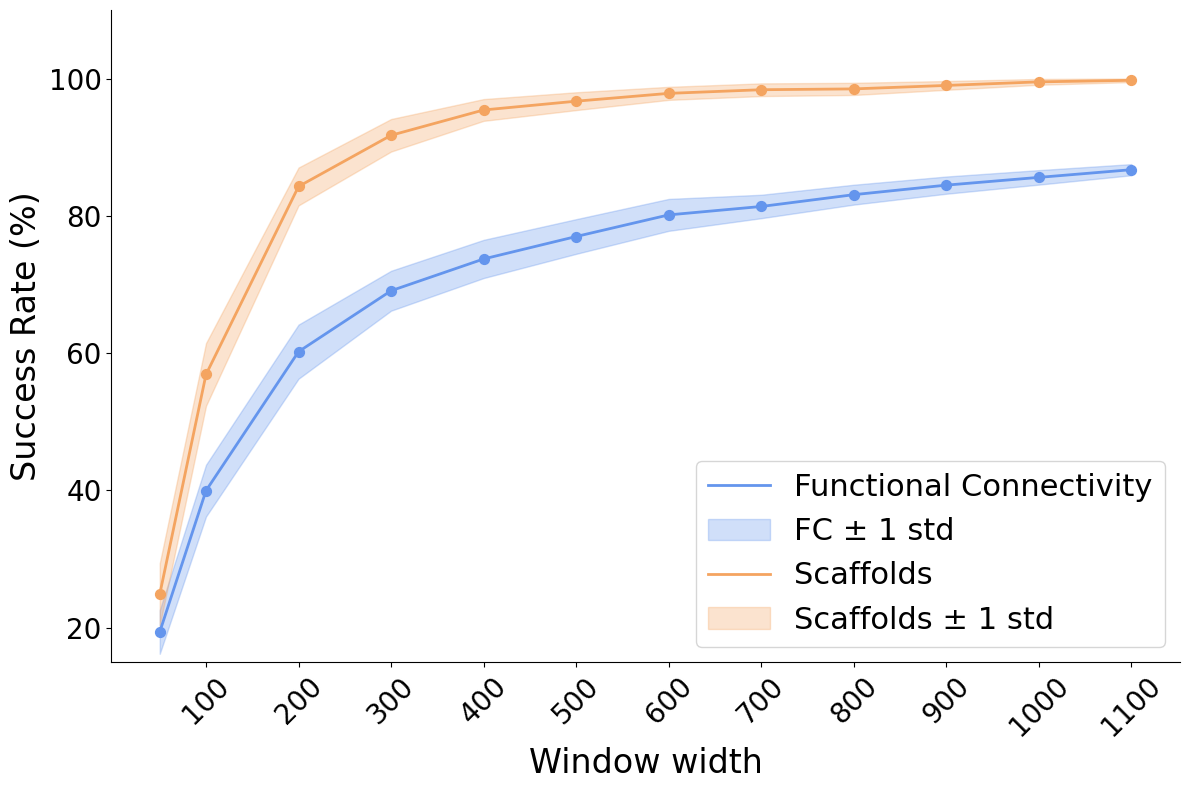


Summary of Success Rate Results:
Window Size | FC Mean ± Std (%) | SC Mean ± Std (%)
-------------------------------------------------------
        50 | 19.4 ± 3.2 | 24.9 ± 4.5
       100 | 40.0 ± 3.8 | 56.9 ± 4.6
       200 | 60.2 ± 3.9 | 84.3 ± 2.8
       300 | 69.1 ± 2.9 | 91.7 ± 2.4
       400 | 73.7 ± 2.8 | 95.4 ± 1.6
       500 | 77.0 ± 2.5 | 96.7 ± 1.3
       600 | 80.2 ± 2.3 | 97.9 ± 0.9
       700 | 81.4 ± 1.7 | 98.4 ± 0.9
       800 | 83.1 ± 1.4 | 98.5 ± 0.9
       900 | 84.5 ± 1.3 | 99.0 ± 0.6
      1000 | 85.6 ± 1.1 | 99.5 ± 0.4
      1100 | 86.7 ± 0.8 | 99.8 ± 0.3

Detailed Success Rate Statistics (SR1 vs SR2):
Window Size | FC SR1 | FC SR2 | SC SR1 | SC SR2
--------------------------------------------------
        50 | 18.9 | 19.9 | 25.1 | 24.7
       100 | 40.2 | 39.7 | 57.5 | 56.3
       200 | 60.3 | 60.2 | 84.3 | 84.2
       300 | 68.9 | 69.3 | 91.8 | 91.7
       400 | 73.2 | 74.2 | 95.9 | 95.0
       500 | 76.3 | 77.7 | 96.9 | 96.5
       600 | 79.3 | 81.0 | 97.8 |

In [12]:
# Plot success rate across window sizes with bootstrap confidence intervals

# Extract data for plotting
x = list(success_rate_fc.keys())
y_fc = [success_rate_fc[w]['mean'] for w in x]
y_sc = [success_rate_sc[w]['mean'] for w in x]

# Standard deviations (used as confidence intervals)
error_fc = [success_rate_fc[w]['std'] for w in x]
error_sc = [success_rate_sc[w]['std'] for w in x]

# Create the plot
plt.figure(figsize=(12,8))

# Plot FC success rate
plt.plot(x, y_fc, label='Functional Connectivity', color='cornflowerblue', linewidth=2)
plt.scatter(x, y_fc, color='cornflowerblue', s=50, zorder=5)
plt.fill_between(x, np.array(y_fc) - np.array(error_fc), 
                 np.array(y_fc) + np.array(error_fc), 
                 alpha=0.3, color='cornflowerblue', label='FC ± 1 std')

# Plot Scaffolds success rate
plt.plot(x, y_sc, label='Scaffolds', color='sandybrown', linewidth=2)
plt.scatter(x, y_sc, color='sandybrown', s=50, zorder=5)
plt.fill_between(x, np.array(y_sc) - np.array(error_sc), 
                 np.array(y_sc) + np.array(error_sc), 
                 alpha=0.3, color='sandybrown', label='Scaffolds ± 1 std')

# Formatting
#plt.title('Success Rate for Different Window Widths (Bootstrap)', fontsize=24)
plt.xlabel('Window width', fontsize=24)
plt.ylabel('Success Rate (%)', fontsize=24)

# Set x-axis ticks
plt.xticks([100,200,300,400,500,600,700,800,900,1000,1100])
plt.tick_params(axis='x', labelsize=20, rotation=45)
plt.tick_params(axis='y', labelsize=20)

# Set y-axis limits (success rate is percentage, so 0-100)
plt.ylim(15, 110)

# Add grid for better readability
#plt.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)

# Legend
plt.legend(fontsize=22, loc='best')

# Remove top and right spines
sb.despine()

# Tight layout
plt.tight_layout()

# Save figure
plt.savefig(os.path.join(figure_folder, 'fig2G_success_rate_bootstrap.png'), dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print("\nSummary of Success Rate Results:")
print("Window Size | FC Mean ± Std (%) | SC Mean ± Std (%)")
print("-" * 55)
for w in sorted(x):
    fc_mean = success_rate_fc[w]['mean']
    fc_std = success_rate_fc[w]['std']
    sc_mean = success_rate_sc[w]['mean']
    sc_std = success_rate_sc[w]['std']
    print(f"{w:10d} | {fc_mean:.1f} ± {fc_std:.1f} | {sc_mean:.1f} ± {sc_std:.1f}")

# Additional detailed statistics
print("\nDetailed Success Rate Statistics (SR1 vs SR2):")
print("Window Size | FC SR1 | FC SR2 | SC SR1 | SC SR2")
print("-" * 50)
for w in sorted(x):
    fc_sr1 = success_rate_fc[w]['sr1_mean']
    fc_sr2 = success_rate_fc[w]['sr2_mean']
    sc_sr1 = success_rate_sc[w]['sr1_mean']
    sc_sr2 = success_rate_sc[w]['sr2_mean']
    print(f"{w:10d} | {fc_sr1:.1f} | {fc_sr2:.1f} | {sc_sr1:.1f} | {sc_sr2:.1f}")

# Panel G2 - Success Rate across Window Sizes with Bootstrap (Random Window Selection) - Samw session

In [14]:
# Compute success rate across different window sizes using bootstrap methods
# For each bootstrap iteration, randomly select one window per subject
widths = [1100,1000,900,800,700,600,500,400,300,200,100,50]
data_dir = sup_folder + '/HCP/100unrelated/schaefer300/no_hp/'
n_subs = 100
n_bootstrap = 100  # Number of bootstrap samples

# Storage for success rate results
success_rate_fc = {}
success_rate_sc = {}

for width in widths:
    print(f'Processing window size: {width}')
    
    fc0 = []
    fc1 = []
    sc0 = []
    sc1 = []
    
    # Load data for this window size
    for sub in os.listdir(data_dir+f'fc/{width}/'):
        fcs = np.load(data_dir+f'fc/{width}/{sub}')
        scs = np.load(data_dir+f'scaffolds/{width}/freq/{sub[:6]}')
        n = fcs.shape[0]
        fc0.append(fcs[:n//2])
        fc1.append(fcs[:n//2])
        sc0.append(scs[:n//2])
        sc1.append(scs[:n//2])
    
    fc0 = np.array(fc0).reshape(-1,300,300)
    fc1 = np.array(fc1).reshape(-1,300,300)
    
    # Threshold FC
    fc0 = np.array([threshold_matrix(f,1).flatten() for f in fc0])
    fc1 = np.array([threshold_matrix(f,1).flatten() for f in fc1])
    
    sc0 = np.array(sc0).reshape(-1,300,300)
    sc1 = np.array(sc1).reshape(-1,300,300)
    sc0 = np.array([s.flatten() for s in sc0])
    sc1 = np.array([s.flatten() for s in sc1])
    
    m = fc0.shape[0]
    n_winps = int(fc0.shape[0]/n_subs)  # n_windows per subject
    
    # Compute correlations fc and scaffolds
    corrs_fc = np.corrcoef(fc0,fc1)[m:,:m]
    corrs_sc = np.corrcoef(sc0,sc1)[m:,:m]
    
    # Bootstrap sampling for success rate with random window selection
    fc_success_rate1_bootstrap = []
    fc_success_rate2_bootstrap = []
    sc_success_rate1_bootstrap = []
    sc_success_rate2_bootstrap = []
    
    for bootstrap_iter in range(n_bootstrap):
        # Create similarity matrices by randomly selecting one window per subject
        fc_similarity_matrix = np.zeros((n_subs, n_subs))
        sc_similarity_matrix = np.zeros((n_subs, n_subs))
        
        # For each subject pair, randomly select one window from each subject
        for i in range(n_subs):
            for j in range(n_subs):
                # Randomly select one window from subject i and one from subject j
                win_i = np.random.randint(0, n_winps)
                win_j = np.random.randint(0, n_winps)
                
                # Get the correlation between these specific windows
                global_idx_i = i * n_winps + win_i
                global_idx_j = j * n_winps + win_j
                
                fc_similarity_matrix[i, j] = corrs_fc[global_idx_i, global_idx_j]
                sc_similarity_matrix[i, j] = corrs_sc[global_idx_i, global_idx_j]
        
        # Compute success rate for this bootstrap sample
        fc_sr1, fc_sr2 = compute_success_rate(fc_similarity_matrix, kind='corr')
        sc_sr1, sc_sr2 = compute_success_rate(sc_similarity_matrix, kind='corr')
        
        fc_success_rate1_bootstrap.append(fc_sr1)
        fc_success_rate2_bootstrap.append(fc_sr2)
        sc_success_rate1_bootstrap.append(sc_sr1)
        sc_success_rate2_bootstrap.append(sc_sr2)
    
    # Compute mean success rate (average of both directions)
    fc_success_rate_mean_bootstrap = [(sr1 + sr2) / 2 for sr1, sr2 in zip(fc_success_rate1_bootstrap, fc_success_rate2_bootstrap)]
    sc_success_rate_mean_bootstrap = [(sr1 + sr2) / 2 for sr1, sr2 in zip(sc_success_rate1_bootstrap, sc_success_rate2_bootstrap)]
    
    # Store results
    success_rate_fc[width] = {
        'mean': np.mean(fc_success_rate_mean_bootstrap),
        'std': np.std(fc_success_rate_mean_bootstrap),
        'bootstrap_samples': fc_success_rate_mean_bootstrap,
        'sr1_mean': np.mean(fc_success_rate1_bootstrap),
        'sr2_mean': np.mean(fc_success_rate2_bootstrap)
    }
    
    success_rate_sc[width] = {
        'mean': np.mean(sc_success_rate_mean_bootstrap),
        'std': np.std(sc_success_rate_mean_bootstrap),
        'bootstrap_samples': sc_success_rate_mean_bootstrap,
        'sr1_mean': np.mean(sc_success_rate1_bootstrap),
        'sr2_mean': np.mean(sc_success_rate2_bootstrap)
    }

print('Success rate computation completed!')

Processing window size: 1100
Processing window size: 1000
Processing window size: 900
Processing window size: 800
Processing window size: 700
Processing window size: 600
Processing window size: 500
Processing window size: 400
Processing window size: 300
Processing window size: 200
Processing window size: 100
Processing window size: 50
Success rate computation completed!


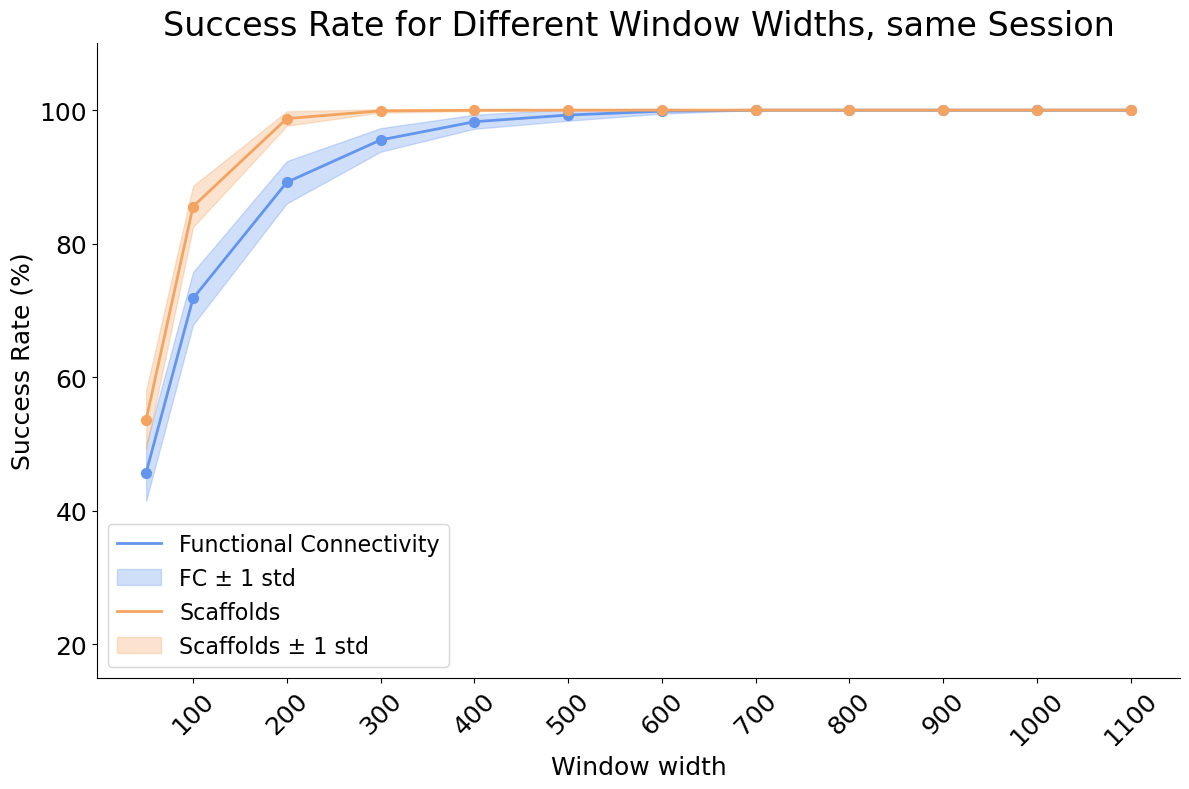


Summary of Success Rate Results:
Window Size | FC Mean ± Std (%) | SC Mean ± Std (%)
-------------------------------------------------------
        50 | 45.7 ± 4.2 | 53.6 ± 4.4
       100 | 71.8 ± 3.9 | 85.6 ± 3.1
       200 | 89.2 ± 3.2 | 98.7 ± 1.1
       300 | 95.5 ± 1.8 | 99.9 ± 0.2
       400 | 98.3 ± 1.1 | 100.0 ± 0.1
       500 | 99.3 ± 0.8 | 100.0 ± 0.0
       600 | 99.8 ± 0.4 | 100.0 ± 0.0
       700 | 100.0 ± 0.0 | 100.0 ± 0.0
       800 | 100.0 ± 0.0 | 100.0 ± 0.0
       900 | 100.0 ± 0.0 | 100.0 ± 0.0
      1000 | 100.0 ± 0.0 | 100.0 ± 0.0
      1100 | 100.0 ± 0.0 | 100.0 ± 0.0

Detailed Success Rate Statistics (SR1 vs SR2):
Window Size | FC SR1 | FC SR2 | SC SR1 | SC SR2
--------------------------------------------------
        50 | 45.8 | 45.6 | 53.5 | 53.7
       100 | 71.9 | 71.7 | 85.6 | 85.6
       200 | 89.0 | 89.4 | 98.7 | 98.8
       300 | 95.5 | 95.6 | 99.9 | 99.9
       400 | 98.3 | 98.3 | 100.0 | 100.0
       500 | 99.3 | 99.3 | 100.0 | 100.0
       600 | 99.

In [16]:
# Plot success rate across window sizes with bootstrap confidence intervals

# Extract data for plotting
x = list(success_rate_fc.keys())
y_fc = [success_rate_fc[w]['mean'] for w in x]
y_sc = [success_rate_sc[w]['mean'] for w in x]

# Standard deviations (used as confidence intervals)
error_fc = [success_rate_fc[w]['std'] for w in x]
error_sc = [success_rate_sc[w]['std'] for w in x]

# Create the plot
plt.figure(figsize=(12,8))

# Plot FC success rate
plt.plot(x, y_fc, label='Functional Connectivity', color='cornflowerblue', linewidth=2)
plt.scatter(x, y_fc, color='cornflowerblue', s=50, zorder=5)
plt.fill_between(x, np.array(y_fc) - np.array(error_fc), 
                 np.array(y_fc) + np.array(error_fc), 
                 alpha=0.3, color='cornflowerblue', label='FC ± 1 std')

# Plot Scaffolds success rate
plt.plot(x, y_sc, label='Scaffolds', color='sandybrown', linewidth=2)
plt.scatter(x, y_sc, color='sandybrown', s=50, zorder=5)
plt.fill_between(x, np.array(y_sc) - np.array(error_sc), 
                 np.array(y_sc) + np.array(error_sc), 
                 alpha=0.3, color='sandybrown', label='Scaffolds ± 1 std')

# Formatting
plt.title('Success Rate for Different Window Widths, same Session', fontsize=24)
plt.xlabel('Window width', fontsize=18)
plt.ylabel('Success Rate (%)', fontsize=18)

# Set x-axis ticks
plt.xticks([100,200,300,400,500,600,700,800,900,1000,1100])
plt.tick_params(axis='x', labelsize=18, rotation=45)
plt.tick_params(axis='y', labelsize=18)

# Set y-axis limits (success rate is percentage, so 0-100)
plt.ylim(15, 110)

# Add grid for better readability
#plt.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)

# Legend
plt.legend(fontsize=16, loc='best')

# Remove top and right spines
sb.despine()

# Tight layout
plt.tight_layout()

# Save figure
#plt.savefig('../figures/supplementary/success_rate_same_session.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print("\nSummary of Success Rate Results:")
print("Window Size | FC Mean ± Std (%) | SC Mean ± Std (%)")
print("-" * 55)
for w in sorted(x):
    fc_mean = success_rate_fc[w]['mean']
    fc_std = success_rate_fc[w]['std']
    sc_mean = success_rate_sc[w]['mean']
    sc_std = success_rate_sc[w]['std']
    print(f"{w:10d} | {fc_mean:.1f} ± {fc_std:.1f} | {sc_mean:.1f} ± {sc_std:.1f}")

# Additional detailed statistics
print("\nDetailed Success Rate Statistics (SR1 vs SR2):")
print("Window Size | FC SR1 | FC SR2 | SC SR1 | SC SR2")
print("-" * 50)
for w in sorted(x):
    fc_sr1 = success_rate_fc[w]['sr1_mean']
    fc_sr2 = success_rate_fc[w]['sr2_mean']
    sc_sr1 = success_rate_sc[w]['sr1_mean']
    sc_sr2 = success_rate_sc[w]['sr2_mean']
    print(f"{w:10d} | {fc_sr1:.1f} | {fc_sr2:.1f} | {sc_sr1:.1f} | {sc_sr2:.1f}")

# Panel H - Effect size across Window Sizes with Bootstrap (Random Window Selection), different sessions

In [18]:
# Compute effect rate across different window sizes using bootstrap methods
# For each bootstrap iteration, randomly select one window per subject
widths = [1100,1000,900,800,700,600,500,400,300,200,100,50]
data_dir = sup_folder + '/HCP/100unrelated/schaefer300/no_hp/'
n_subs = 100
n_bootstrap = 100  # Number of bootstrap samples

# Storage for effect rate results
effect_size_fc_different_sessions = {}
effect_size_sc_different_sessions = {}

fc_effect_size_bootstrap = []
sc_effect_size_bootstrap = []

for width in widths:
    print(f'Processing window size: {width}')
    
    fc0 = []
    fc1 = []
    sc0 = []
    sc1 = []
    
    # Load data for this window size
    for sub in os.listdir(data_dir+f'fc/{width}/'):
        fcs = np.load(data_dir+f'fc/{width}/{sub}')
        scs = np.load(data_dir+f'scaffolds/{width}/freq/{sub[:6]}')
        n = fcs.shape[0]
        fc0.append(fcs[:n//2])
        fc1.append(fcs[n//2:])
        sc0.append(scs[:n//2])
        sc1.append(scs[n//2:])
    
    fc0 = np.array(fc0).reshape(-1,300,300)
    fc1 = np.array(fc1).reshape(-1,300,300)
    
    # Threshold FC
    fc0 = np.array([threshold_matrix(f,1).flatten() for f in fc0])
    fc1 = np.array([threshold_matrix(f,1).flatten() for f in fc1])
    
    sc0 = np.array(sc0).reshape(-1,300,300)
    sc1 = np.array(sc1).reshape(-1,300,300)
    sc0 = np.array([s.flatten() for s in sc0])
    sc1 = np.array([s.flatten() for s in sc1])
    
    m = fc0.shape[0]
    n_winps = int(fc0.shape[0]/n_subs)  # n_windows per subject
    
    # Compute correlations fc and scaffolds
    corrs_fc = np.corrcoef(fc0,fc1)[m:,:m]
    corrs_sc = np.corrcoef(sc0,sc1)[m:,:m]
    # Bootstrap sampling for effect size with random window selection
    fc_effect_size_bootstrap = []
    sc_effect_size_bootstrap = []
    fc_effect_size_bootstrap = []
    sc_effect_size_bootstrap = []
    
    for bootstrap_iter in range(n_bootstrap):

        # Create similarity matrices by randomly selecting one window per subject
        fc_similarity_matrix = np.zeros((n_subs, n_subs))
        sc_similarity_matrix = np.zeros((n_subs, n_subs))
        
        # For each subject pair, randomly select one window from each subject
        for i in range(n_subs):
            for j in range(n_subs):
                # Randomly select one window from subject i and one from subject j
                win_i = np.random.randint(0, n_winps)
                win_j = np.random.randint(0, n_winps)
                
                # Get the correlation between these specific windows
                global_idx_i = i * n_winps + win_i
                global_idx_j = j * n_winps + win_j
                
                fc_similarity_matrix[i, j] = corrs_fc[global_idx_i, global_idx_j]
                sc_similarity_matrix[i, j] = corrs_sc[global_idx_i, global_idx_j]
        
        # Compute effect size for this bootstrap sample
        fc_effect_size_bootstrap.append(compute_effect_size(fc_similarity_matrix, kind='corr'))
        sc_effect_size_bootstrap.append(compute_effect_size(sc_similarity_matrix, kind='corr'))

    
    # Store results
    effect_size_fc_different_sessions[width] = {
        'mean': np.mean(fc_effect_size_bootstrap),
        'std': np.std(fc_effect_size_bootstrap),
        'bootstrap_samples': fc_effect_size_bootstrap,
    }

    effect_size_sc_different_sessions[width] = {
        'mean': np.mean(sc_effect_size_bootstrap),
        'std': np.std(sc_effect_size_bootstrap),
        'bootstrap_samples': sc_effect_size_bootstrap,
        # 'sr1_mean': np.mean(sc_success_rate1_bootstrap),
        # 'sr2_mean': np.mean(sc_success_rate2_bootstrap)
    }

print('Effect size computation completed!')

Processing window size: 1100
Processing window size: 1000
Processing window size: 900
Processing window size: 800
Processing window size: 700
Processing window size: 600
Processing window size: 500
Processing window size: 400
Processing window size: 300
Processing window size: 200
Processing window size: 100
Processing window size: 50
Effect size computation completed!


In [19]:
for width in widths:
    print(f'Processing window size: {width}')
    
    fc0 = []
    fc1 = []
    sc0 = []
    sc1 = []
    
    # Load data for this window size
    for sub in os.listdir(data_dir+f'fc/{width}/'):
        fcs = np.load(data_dir+f'fc/{width}/{sub}')
        scs = np.load(data_dir+f'scaffolds/{width}/freq/{sub[:6]}')
        n = fcs.shape[0]
        fc0.append(fcs[:n//2])
        fc1.append(fcs[n//2:])
        sc0.append(scs[:n//2])
        sc1.append(scs[n//2:])
    
    print(fcs.shape)

Processing window size: 1100
(4, 300, 300)
Processing window size: 1000
(6, 300, 300)
Processing window size: 900
(8, 300, 300)
Processing window size: 800
(10, 300, 300)
Processing window size: 700
(12, 300, 300)
Processing window size: 600
(12, 300, 300)
Processing window size: 500
(12, 300, 300)
Processing window size: 400
(12, 300, 300)
Processing window size: 300
(12, 300, 300)
Processing window size: 200
(12, 300, 300)
Processing window size: 100
(12, 300, 300)
Processing window size: 50
(12, 300, 300)


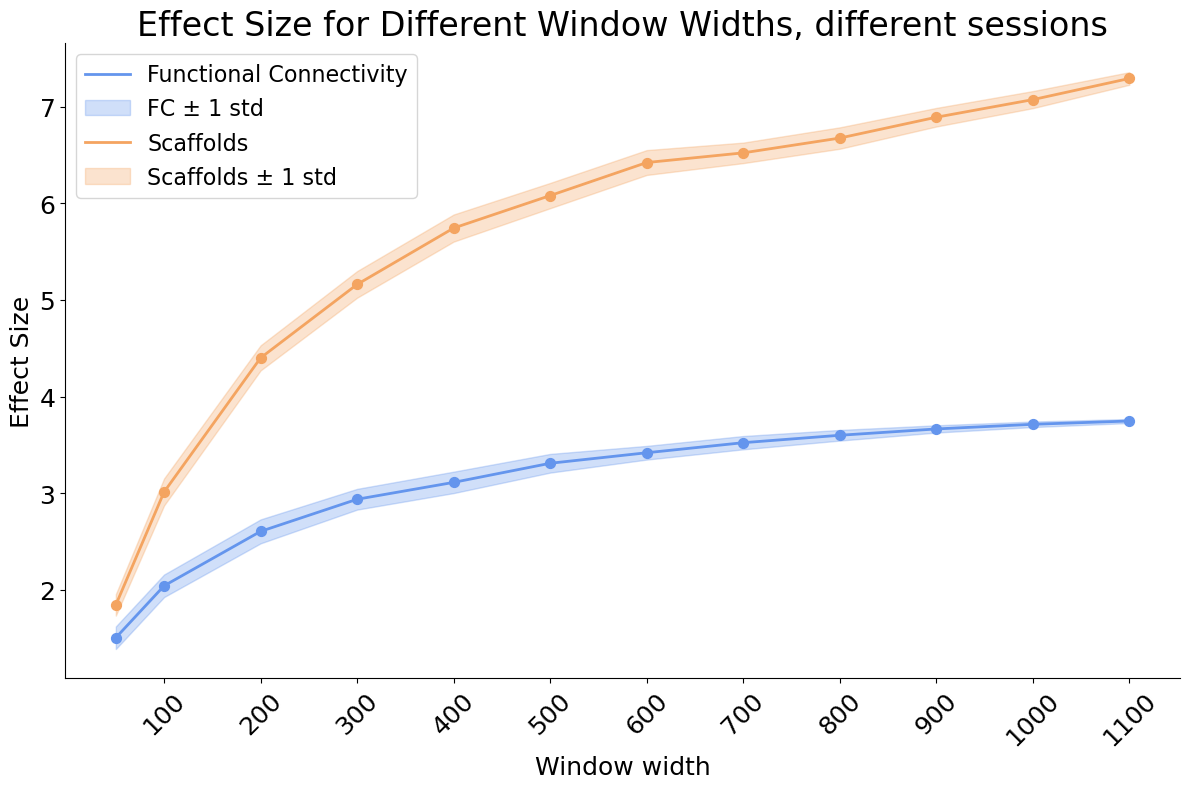


Detailed Effect Size Statistics (SR1 vs SR2):
Window Size | FC SR1 | FC SR2 | SC SR1 | SC SR2
--------------------------------------------------


In [21]:
# Plot effect size across window sizes with bootstrap confidence intervals

# Extract data for plotting
x = list(effect_size_fc_different_sessions.keys())
y_fc = [effect_size_fc_different_sessions[w]['mean'] for w in x]
y_sc = [effect_size_sc_different_sessions[w]['mean'] for w in x]

# Standard deviations (used as confidence intervals)
error_fc = [effect_size_fc_different_sessions[w]['std'] for w in x]
error_sc = [effect_size_sc_different_sessions[w]['std'] for w in x]

# Create the plot
plt.figure(figsize=(12,8))

# Plot FC effect size
plt.plot(x, y_fc, label='Functional Connectivity', color='cornflowerblue', linewidth=2)
plt.scatter(x, y_fc, color='cornflowerblue', s=50, zorder=5)
plt.fill_between(x, np.array(y_fc) - np.array(error_fc), 
                 np.array(y_fc) + np.array(error_fc), 
                 alpha=0.3, color='cornflowerblue', label='FC ± 1 std')

# Plot Scaffolds effect size
plt.plot(x, y_sc, label='Scaffolds', color='sandybrown', linewidth=2)
plt.scatter(x, y_sc, color='sandybrown', s=50, zorder=5)
plt.fill_between(x, np.array(y_sc) - np.array(error_sc), 
                 np.array(y_sc) + np.array(error_sc), 
                 alpha=0.3, color='sandybrown', label='Scaffolds ± 1 std')

# Formatting
plt.title('Effect Size for Different Window Widths, different sessions', fontsize=24)
plt.xlabel('Window width', fontsize=18)
plt.ylabel('Effect Size', fontsize=18)

# Set x-axis ticks
plt.xticks([100,200,300,400,500,600,700,800,900,1000,1100])
plt.tick_params(axis='x', labelsize=18, rotation=45)
plt.tick_params(axis='y', labelsize=18)

# Set y-axis limits (effect size is not constrained, so 0-1)
#plt.ylim(0, 1)

# Add grid for better readability
#plt.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)

# Legend
plt.legend(fontsize=16, loc='best')

# Remove top and right spines
sb.despine()

# Tight layout
plt.tight_layout()

# Save figure
#plt.savefig('../figures/supplementary/effect_size_different_sessions.pdf', dpi=300, bbox_inches='tight')
plt.show()

# # Print summary statistics
# print("\nSummary of Effect Size Results:")
# print("Window Size | FC Mean ± Std (%) | SC Mean ± Std (%)")
# print("-" * 55)
# for w in sorted(x):
#     fc_mean = effect_size_fc[w]['mean']
#     fc_std = effect_size_fc[w]['std']
#     sc_mean = effect_size_sc[w]['mean']
#     sc_std = effect_size_sc[w]['std']
#     print(f"{w:10d} | {fc_mean:.1f} ± {fc_std:.1f} | {sc_mean:.1f} ± {sc_std:.1f}")

# Additional detailed statistics
print("\nDetailed Effect Size Statistics (SR1 vs SR2):")
print("Window Size | FC SR1 | FC SR2 | SC SR1 | SC SR2")
print("-" * 50)

# Panel H - Effect size across Window Sizes with Bootstrap (Random Window Selection), same sessions

In [23]:
# Compute effect rate across different window sizes using bootstrap methods
# For each bootstrap iteration, randomly select one window per subject
widths = [1100,1000,900,800,700,600,500,400,300,200,100,50]
data_dir = sup_folder + 'HCP/100unrelated/schaefer300/no_hp/'
n_subs = 100
n_bootstrap = 100  # Number of bootstrap samples

# Storage for effect rate results
effect_size_fc_same_sessions = {}
effect_size_sc_same_sessions = {}

fc_effect_size_bootstrap = []
sc_effect_size_bootstrap = []

for width in widths:
    print(f'Processing window size: {width}')
    
    fc0 = []
    fc1 = []
    sc0 = []
    sc1 = []
    
    # Load data for this window size
    for sub in os.listdir(data_dir+f'fc/{width}/'):
        fcs = np.load(data_dir+f'fc/{width}/{sub}')
        scs = np.load(data_dir+f'scaffolds/{width}/freq/{sub[:6]}')
        n = fcs.shape[0]
        fc0.append(fcs[:n//2])
        fc1.append(fcs[:n//2])
        sc0.append(scs[:n//2])
        sc1.append(scs[:n//2])
    
    fc0 = np.array(fc0).reshape(-1,300,300)
    fc1 = np.array(fc1).reshape(-1,300,300)
    
    # Threshold FC
    fc0 = np.array([threshold_matrix(f,1).flatten() for f in fc0])
    fc1 = np.array([threshold_matrix(f,1).flatten() for f in fc1])
    
    sc0 = np.array(sc0).reshape(-1,300,300)
    sc1 = np.array(sc1).reshape(-1,300,300)
    sc0 = np.array([s.flatten() for s in sc0])
    sc1 = np.array([s.flatten() for s in sc1])
    
    m = fc0.shape[0]
    n_winps = int(fc0.shape[0]/n_subs)  # n_windows per subject
    
    # Compute correlations fc and scaffolds
    corrs_fc = np.corrcoef(fc0,fc1)[m:,:m]
    corrs_sc = np.corrcoef(sc0,sc1)[m:,:m]
    # Bootstrap sampling for effect size with random window selection
    fc_effect_size_bootstrap = []
    sc_effect_size_bootstrap = []
    fc_effect_size_bootstrap = []
    sc_effect_size_bootstrap = []
    
    for bootstrap_iter in range(n_bootstrap):

        # Create similarity matrices by randomly selecting one window per subject
        fc_similarity_matrix = np.zeros((n_subs, n_subs))
        sc_similarity_matrix = np.zeros((n_subs, n_subs))
        
        # For each subject pair, randomly select one window from each subject
        for i in range(n_subs):
            for j in range(n_subs):
                # Randomly select one window from subject i and one from subject j
                win_i = np.random.randint(0, n_winps)
                win_j = np.random.randint(0, n_winps)
                
                # Get the correlation between these specific windows
                global_idx_i = i * n_winps + win_i
                global_idx_j = j * n_winps + win_j
                
                fc_similarity_matrix[i, j] = corrs_fc[global_idx_i, global_idx_j]
                sc_similarity_matrix[i, j] = corrs_sc[global_idx_i, global_idx_j]
        
        # Compute effect size for this bootstrap sample
        fc_effect_size_bootstrap.append(compute_effect_size(fc_similarity_matrix, kind='corr'))
        sc_effect_size_bootstrap.append(compute_effect_size(sc_similarity_matrix, kind='corr'))

    
    # Store results
    effect_size_fc_same_sessions[width] = {
        'mean': np.mean(fc_effect_size_bootstrap),
        'std': np.std(fc_effect_size_bootstrap),
        'bootstrap_samples': fc_effect_size_bootstrap,
    }

    effect_size_sc_same_sessions[width] = {
        'mean': np.mean(sc_effect_size_bootstrap),
        'std': np.std(sc_effect_size_bootstrap),
        'bootstrap_samples': sc_effect_size_bootstrap,
        # 'sr1_mean': np.mean(sc_success_rate1_bootstrap),
        # 'sr2_mean': np.mean(sc_success_rate2_bootstrap)
    }

print('Effect size computation completed!')

Processing window size: 1100
Processing window size: 1000
Processing window size: 900
Processing window size: 800
Processing window size: 700
Processing window size: 600
Processing window size: 500
Processing window size: 400
Processing window size: 300
Processing window size: 200
Processing window size: 100
Processing window size: 50
Effect size computation completed!


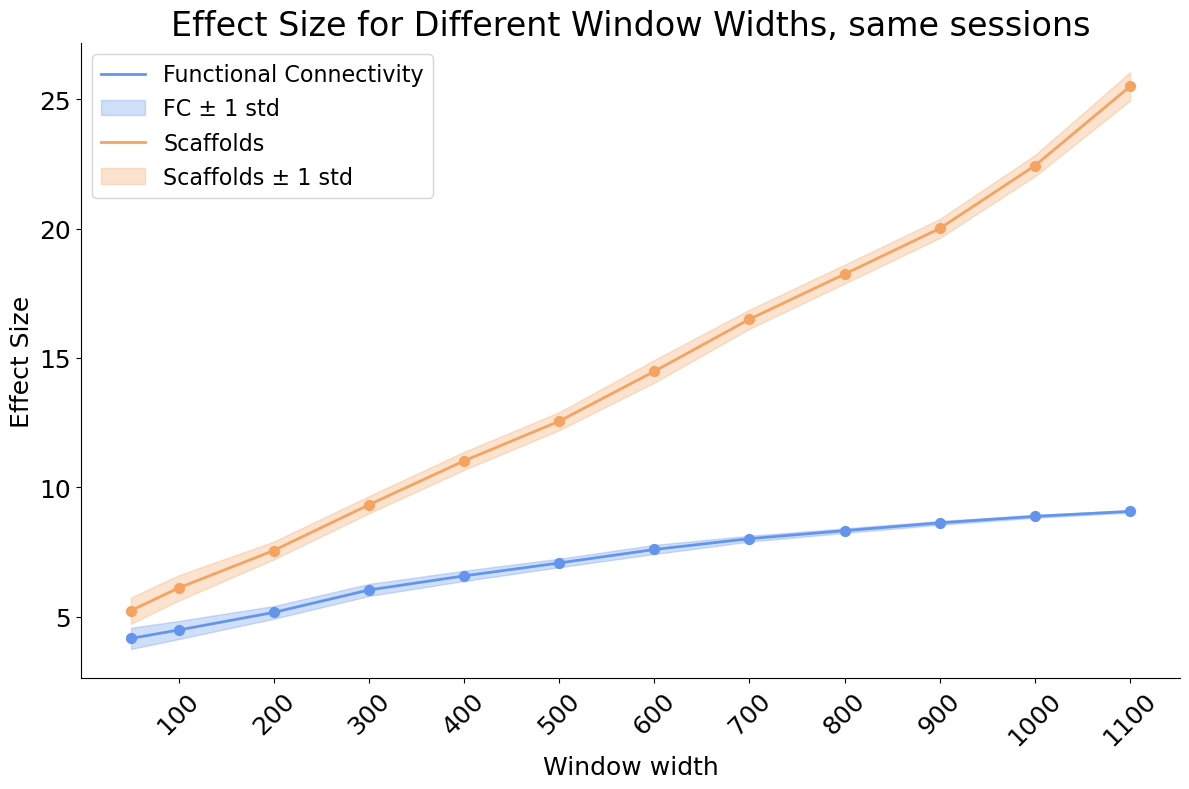


Detailed Effect Size Statistics (SR1 vs SR2):
Window Size | FC SR1 | FC SR2 | SC SR1 | SC SR2
--------------------------------------------------


In [25]:
# Plot effect size across window sizes with bootstrap confidence intervals

# Extract data for plotting
x = list(effect_size_fc_same_sessions.keys())
y_fc = [effect_size_fc_same_sessions[w]['mean'] for w in x]
y_sc = [effect_size_sc_same_sessions[w]['mean'] for w in x]

# Standard deviations (used as confidence intervals)
error_fc = [effect_size_fc_same_sessions[w]['std'] for w in x]
error_sc = [effect_size_sc_same_sessions[w]['std'] for w in x]

# Create the plot
plt.figure(figsize=(12,8))

# Plot FC effect size
plt.plot(x, y_fc, label='Functional Connectivity', color='cornflowerblue', linewidth=2)
plt.scatter(x, y_fc, color='cornflowerblue', s=50, zorder=5)
plt.fill_between(x, np.array(y_fc) - np.array(error_fc), 
                 np.array(y_fc) + np.array(error_fc), 
                 alpha=0.3, color='cornflowerblue', label='FC ± 1 std')

# Plot Scaffolds effect size
plt.plot(x, y_sc, label='Scaffolds', color='sandybrown', linewidth=2)
plt.scatter(x, y_sc, color='sandybrown', s=50, zorder=5)
plt.fill_between(x, np.array(y_sc) - np.array(error_sc), 
                 np.array(y_sc) + np.array(error_sc), 
                 alpha=0.3, color='sandybrown', label='Scaffolds ± 1 std')

# Formatting
plt.title('Effect Size for Different Window Widths, same sessions', fontsize=24)
plt.xlabel('Window width', fontsize=18)
plt.ylabel('Effect Size', fontsize=18)

# Set x-axis ticks
plt.xticks([100,200,300,400,500,600,700,800,900,1000,1100])
plt.tick_params(axis='x', labelsize=18, rotation=45)
plt.tick_params(axis='y', labelsize=18)

# Set y-axis limits (effect size is not constrained, so 0-1)
#plt.ylim(0, 1)

# Add grid for better readability
#plt.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)

# Legend
plt.legend(fontsize=16, loc='best')

# Remove top and right spines
sb.despine()

# Tight layout
plt.tight_layout()

# Save figure
#plt.savefig('../figures/supplementary/effect_size_same_session.pdf', dpi=300, bbox_inches='tight')
plt.show()

# # Print summary statistics
# print("\nSummary of Effect Size Results:")
# print("Window Size | FC Mean ± Std (%) | SC Mean ± Std (%)")
# print("-" * 55)
# for w in sorted(x):
#     fc_mean = effect_size_fc[w]['mean']
#     fc_std = effect_size_fc[w]['std']
#     sc_mean = effect_size_sc[w]['mean']
#     sc_std = effect_size_sc[w]['std']
#     print(f"{w:10d} | {fc_mean:.1f} ± {fc_std:.1f} | {sc_mean:.1f} ± {sc_std:.1f}")

# Additional detailed statistics
print("\nDetailed Effect Size Statistics (SR1 vs SR2):")
print("Window Size | FC SR1 | FC SR2 | SC SR1 | SC SR2")
print("-" * 50)

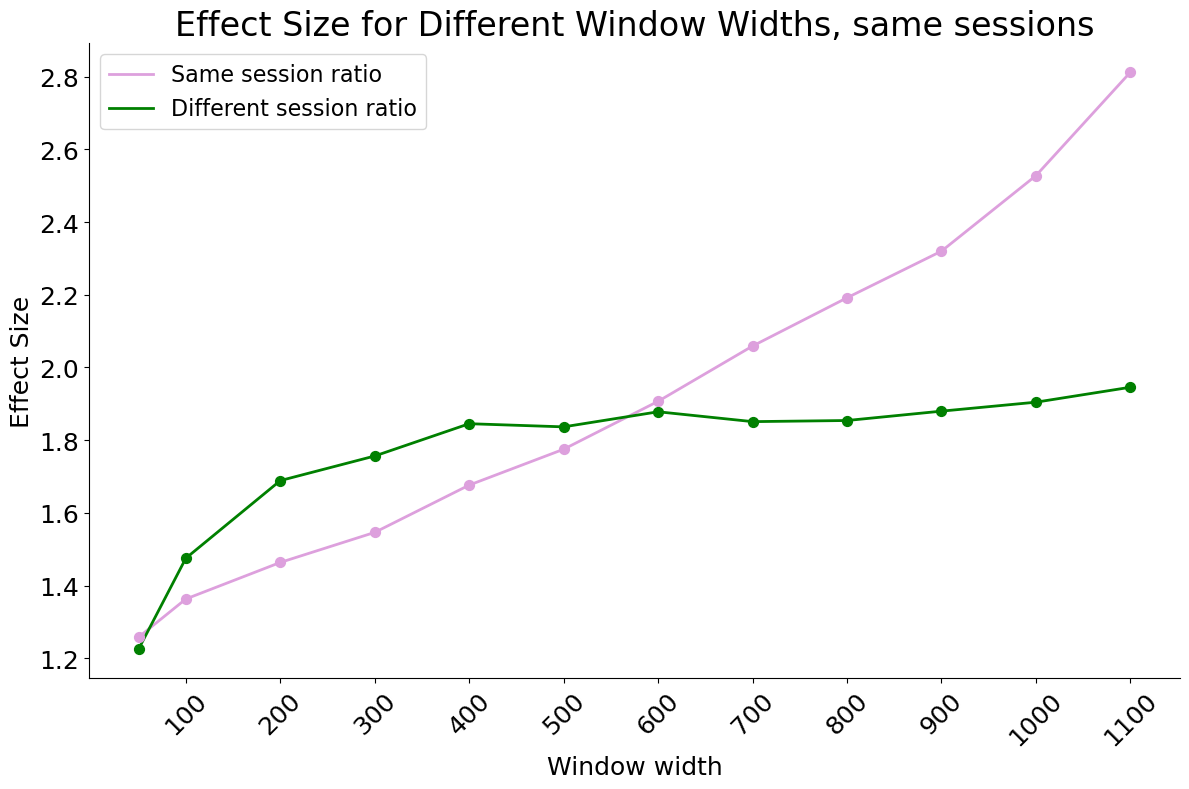

In [27]:
# Extract data for plotting
x = list(effect_size_fc_same_sessions.keys())
y_fc_same_session = [effect_size_fc_same_sessions[w]['mean'] for w in x]
y_sc_same_session = [effect_size_sc_same_sessions[w]['mean'] for w in x]

y_fc_different_session = [effect_size_fc_different_sessions[w]['mean'] for w in x]
y_sc_different_session = [effect_size_sc_different_sessions[w]['mean'] for w in x]

same_session_ratio = np.array(y_sc_same_session) / np.array(y_fc_same_session)
different_session_ratio = np.array(y_sc_different_session) / np.array(y_fc_different_session)

# Create the plot
plt.figure(figsize=(12,8))

# Plot ratio of scaffolds to functional connectivity for same sessions
plt.plot(x, same_session_ratio, label='Same session ratio', color='plum', linewidth=2)
plt.scatter(x, same_session_ratio, color='plum', s=50, zorder=5)

# Plot ratio of scaffolds to functional connectivity for different sessions
plt.plot(x, different_session_ratio, label='Different session ratio', color='green', linewidth=2)
plt.scatter(x, different_session_ratio, color='green', s=50, zorder=5)

# Formatting
plt.title('Effect Size for Different Window Widths, same sessions', fontsize=24)
plt.xlabel('Window width', fontsize=18)
plt.ylabel('Effect Size', fontsize=18)

# Set x-axis ticks
plt.xticks([100,200,300,400,500,600,700,800,900,1000,1100])
plt.tick_params(axis='x', labelsize=18, rotation=45)
plt.tick_params(axis='y', labelsize=18)

# Set y-axis limits (effect size is not constrained, so 0-1)
#plt.ylim(0, 1)

# Add grid for better readability
#plt.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)

# Legend
plt.legend(fontsize=16, loc='best')

# Remove top and right spines
sb.despine()

# Tight layout
plt.tight_layout()

# Save figure
#plt.savefig('../figures/supplementary/ratio.pdf', dpi=300, bbox_inches='tight')
plt.show()